In [1]:
#Cella 1
!pip install -q trimesh

import os
import glob
import json
import time
import random
import numpy as np
import cv2
from PIL import Image
import matplotlib.pyplot as plt

import scipy.ndimage as ndimage
import scipy.io as sio
from skimage.metrics import structural_similarity as ssim_metric
from skimage.metrics import peak_signal_noise_ratio as psnr_metric
from skimage.measure import marching_cubes
import trimesh

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Riproducibilità
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo in uso: {DEVICE}")

Dispositivo in uso: cuda


In [2]:
#Cella 2
class Config:
    IMG_SIZE = 128
    NUM_SLICES = 10
    SLICE_INTERVAL = 5.0   # \Delta z = 5 (Sez. IV-A)
    ALPHA_DECAY = 0.1      # \alpha = 0.1 (Sez. IV-A)
    BATCH_SIZE = 16        # Batch size = 16 (Sez. IV-D & V)
    EPOCHS = 100           # 100 Epoche (Sez. IV-D & V)
    LR = 1e-4              # Learning rate = 1e-4 (Sez. V)
    BETA1 = 0.5            # Adam beta1 = 0.5 (Sez. V)
    BETA2 = 0.999          # Adam beta2 = 0.999 (Sez. V)
    LAMBDA_L1 = 50.0       # Peso L_recon rispetto a L_GAN (Eq. 4)
    ROI_THRESHOLD = 0.7    # Soglia globale \tau = 0.7 (Eq. 5)
    S_XY = 0.5             # Pixel spacing default: 0.5 mm (Sez. IV-E)
    S_Z = 1.0              # Slice spacing default: 1.0 mm (Sez. IV-E)
    MAX_IMAGES = 800       # Limite immagini (nel paper sono 745)
    OUTPUT_DIR = "/kaggle/working"

os.makedirs(Config.OUTPUT_DIR, exist_ok=True)


def build_seed_and_target_volumes(img_2d: np.ndarray):
    """
    Implementa la Sez. IV-A (Eq. 1):
    Dato un array 2D normalizzato [128, 128] in [0, 1], genera:
    - seed_vol V^(0): [1, 10, 128, 128] con decadimento lungo z (Eq. 1)
    - target_vol V  : [1, 10, 128, 128] volume 3D coerente con profilo anatomico
                      lungo z e filtraggio 3D per preservare parenchima e lesione.
    """
    H, W = img_2d.shape
    D = Config.NUM_SLICES
    
    # 1. Seed Volume V^(0) secondo Eq. (1): z_i = (i - 1) * \Delta z
    seed_slices = []
    for i in range(D):
        z_i = i * Config.SLICE_INTERVAL
        # Attenuazione lungo la profondità z_i
        decay_factor = np.exp(-Config.ALPHA_DECAY * (z_i / Config.SLICE_INTERVAL))
        slice_i = img_2d * decay_factor
        seed_slices.append(slice_i)
    
    seed_vol = np.stack(seed_slices, axis=0).astype(np.float32) # [10, 128, 128]
    # Normalizzazione Min-Max a [0, 1] come richiesto da Eq. (1)
    s_min, s_max = seed_vol.min(), seed_vol.max()
    if s_max - s_min > 1e-6:
        seed_vol = (seed_vol - s_min) / (s_max - s_min)
        
    # 2. Target Volume V (Riferimento 3D con continuità inter-slice e inviluppo 3D)
    # Moduliamo la profondità in base alla densità radiografica locale così che
    # il tessuto denso e le lesioni (iperintense) abbiano consistenza volumetrica reale
    # nelle slice centrali e si attenuino verso le slice esterne.
    z_coords = np.linspace(-1.0, 1.0, D)[:, None, None] # [10, 1, 1]
    # Lo spessore locale dipende dall'intensità 2D (più denso = più esteso su z)
    local_thickness = np.clip(img_2d[None, :, :] * 1.15, 0.15, 1.0)
    envelope_3d = np.exp(-0.5 * (z_coords / local_thickness) ** 2)
    
    target_vol = (img_2d[None, :, :] * envelope_3d).astype(np.float32)
    target_vol = ndimage.gaussian_filter(target_vol, sigma=(0.6, 0.5, 0.5))
    t_min, t_max = target_vol.min(), target_vol.max()
    if t_max - t_min > 1e-6:
        target_vol = (target_vol - t_min) / (t_max - t_min)
        
    # Aggiungiamo la dimensione canale -> [1, 10, 128, 128] (PyTorch Conv3d: C, D, H, W)
    return seed_vol[None, ...], target_vol[None, ...]


def generate_synthetic_mammogram(size=128):
    """
    Fallback: Genera una mammografia 2D sintetica realistica (profilo mammario +
    tessuto fibroglandolare interno + 1 o 2 lesioni iperintense > 0.7)
    nel caso in cui il notebook venga eseguito senza dataset allegato.
    """
    y, x = np.ogrid[:size, :size]
    # Profilo a cupola della mammella sul lato sinistro
    cx, cy = 0, size // 2
    rx, ry = int(size * 0.72), int(size * 0.45)
    breast_mask = ((x - cx)**2 / (rx**2 + 1e-5) + (y - cy)**2 / (ry**2 + 1e-5)) <= 1.0
    dist_from_chest = np.clip(1.0 - (x / (rx + 1e-5)) * 0.55, 0.0, 1.0)
    
    # Texture parenchimale multi-scala
    noise1 = ndimage.gaussian_filter(np.random.rand(size, size), sigma=3.5)
    noise2 = ndimage.gaussian_filter(np.random.rand(size, size), sigma=1.5)
    parenchyma = 0.45 * noise1 + 0.25 * noise2
    parenchyma = (parenchyma - parenchyma.min()) / (parenchyma.max() - parenchyma.min() + 1e-6)
    
    img = breast_mask * dist_from_chest * (0.20 + 0.48 * parenchyma)
    
    # Inserimento lesione tumorale iperintensa (intensità > 0.75)
    num_lesions = random.choice([1, 2])
    for _ in range(num_lesions):
        lx = random.randint(int(size * 0.18), int(size * 0.48))
        ly = random.randint(int(size * 0.35), int(size * 0.65))
        lr = random.uniform(4.0, 9.0)
        lesion_profile = np.exp(-((x - lx)**2 + (y - ly)**2) / (2 * (lr**2)))
        img = np.maximum(img, breast_mask * lesion_profile * random.uniform(0.82, 0.98))
        
    img = np.clip(img, 0.0, 1.0).astype(np.float32)
    return (img * 255).astype(np.uint8)


class Mammogram2DTo3DDataset(Dataset):
    def __init__(self, image_paths, augment=False):
        self.image_paths = image_paths
        self.augment = augment
        self.clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

    def __len__(self):
        return len(self.image_paths)

    def _preprocess_2d(self, img_gray: np.ndarray) -> np.ndarray:
        # Clipping intensità estreme (1° e 99° percentile - Sez. III)
        p1, p99 = np.percentile(img_gray, (1, 99))
        if p99 > p1:
            img_gray = np.clip(img_gray, p1, p99)
            img_gray = ((img_gray - p1) / (p99 - p1) * 255.0).astype(np.uint8)
            
        # Resize a 128x128
        img_resized = cv2.resize(img_gray, (Config.IMG_SIZE, Config.IMG_SIZE), interpolation=cv2.INTER_AREA)
        
        if self.augment:
            # 1. Flip orizzontale (p = 0.5)
            if random.random() < 0.5:
                img_resized = cv2.flip(img_resized, 1)
            # 2. CLAHE opzionale
            if random.random() < 0.3:
                img_resized = self.clahe.apply(img_resized)
            # 3. Rotazione (±5°), Traslazione (±5%) e Scaling (±5%)
            angle = random.uniform(-5.0, 5.0)
            scale = random.uniform(0.95, 1.05)
            tx = random.uniform(-0.05, 0.05) * Config.IMG_SIZE
            ty = random.uniform(-0.05, 0.05) * Config.IMG_SIZE
            M = cv2.getRotationMatrix2D((Config.IMG_SIZE / 2, Config.IMG_SIZE / 2), angle, scale)
            M[0, 2] += tx
            M[1, 2] += ty
            img_resized = cv2.warpAffine(img_resized, M, (Config.IMG_SIZE, Config.IMG_SIZE), borderMode=cv2.BORDER_CONSTANT, borderValue=0)

        img_float = img_resized.astype(np.float32) / 255.0
        
        if self.augment:
            # 4. Random gamma (0.9 - 1.1)
            gamma = random.uniform(0.9, 1.1)
            img_float = np.power(np.clip(img_float, 1e-6, 1.0), gamma)
            # 5. Gaussian noise (\sigma <= 0.01)
            sigma = random.uniform(0.0, 0.01)
            img_float = img_float + np.random.normal(0, sigma, img_float.shape).astype(np.float32)

        # Min-Max normalization a [0, 1]
        imin, imax = img_float.min(), img_float.max()
        if imax - imin > 1e-6:
            img_float = (img_float - imin) / (imax - imin)
        return np.clip(img_float, 0.0, 1.0).astype(np.float32)

    def __getitem__(self, idx):
        path = self.image_paths[idx]
        if path.startswith("SYNTHETIC_"):
            raw_img = generate_synthetic_mammogram(Config.IMG_SIZE)
        else:
            raw_img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
            if raw_img is None:
                raw_img = generate_synthetic_mammogram(Config.IMG_SIZE)
                
        img_2d = self._preprocess_2d(raw_img)
        seed_vol, target_vol = build_seed_and_target_volumes(img_2d)
        return torch.from_numpy(seed_vol), torch.from_numpy(target_vol), torch.from_numpy(img_2d)


# Ricerca automatica immagini mammografiche in /kaggle/input
all_image_files = []
for ext in ("*.jpg", "*.jpeg", "*.png", "*.pgm"):
    all_image_files.extend(glob.glob(f"/kaggle/input/**/*{ext}", recursive=True))

if len(all_image_files) >= 20:
    print(f"Trovate {len(all_image_files)} immagini reali in /kaggle/input!")
    random.shuffle(all_image_files)
    all_image_files = all_image_files[:Config.MAX_IMAGES]
else:
    print("Nessun dataset trovato in /kaggle/input: generazione di 250 mammografie sintetiche per il training.")
    all_image_files = [f"SYNTHETIC_{i}" for i in range(250)]

# Split 70% Train / 15% Val / 15% Test (Sez. III & V)
n_total = len(all_image_files)
n_train = int(0.70 * n_total)
n_val = int(0.15 * n_total)

train_files = all_image_files[:n_train]
val_files = all_image_files[n_train:n_train + n_val]
test_files = all_image_files[n_train + n_val:]

train_loader = DataLoader(Mammogram2DTo3DDataset(train_files, augment=True), batch_size=Config.BATCH_SIZE, shuffle=True, drop_last=False)
val_loader   = DataLoader(Mammogram2DTo3DDataset(val_files, augment=False), batch_size=Config.BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(Mammogram2DTo3DDataset(test_files, augment=False), batch_size=Config.BATCH_SIZE, shuffle=False)

print(f"Split completato -> Train: {len(train_files)} | Val: {len(val_files)} | Test: {len(test_files)}")

Trovate 10237 immagini reali in /kaggle/input!
Split completato -> Train: 560 | Val: 120 | Test: 120


In [3]:
class UNet3DGenerator(nn.Module):
    """
    Generatore 3D U-Net pulito e robusto.
    Input : [B, 1, 10, 128, 128]
    Output: [B, 1, 10, 128, 128] con attivazione Sigmoid in [0, 1]
    """
    def __init__(self):
        super().__init__()
        # Encoder Level 1: [B, 1, 10, 128, 128] -> [B, 64, 10, 128, 128]
        self.enc1 = nn.Sequential(
            nn.Conv3d(1, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm3d(64),
            nn.ReLU(inplace=True),
            nn.Conv3d(64, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm3d(64),
            nn.ReLU(inplace=True)
        )
        self.pool1 = nn.MaxPool3d(kernel_size=2, stride=2) # -> [B, 64, 5, 64, 64]

        # Encoder Level 2: [B, 64, 5, 64, 64] -> [B, 128, 5, 64, 64]
        self.enc2 = nn.Sequential(
            nn.Conv3d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm3d(128),
            nn.ReLU(inplace=True),
            nn.Conv3d(128, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm3d(128),
            nn.ReLU(inplace=True)
        )
        self.pool2 = nn.MaxPool3d(kernel_size=2, stride=2) # -> [B, 128, 2, 32, 32]

        # Bottleneck: [B, 128, 2, 32, 32] -> [B, 256, 2, 32, 32]
        self.bottleneck = nn.Sequential(
            nn.Conv3d(128, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm3d(256),
            nn.ReLU(inplace=True)
        )

        # Decoder Up 1
        self.up1 = nn.ConvTranspose3d(
            256, 128, kernel_size=3, stride=2, padding=1, output_padding=1, bias=False
        )
        # Dopo la concatenazione con e2 (128 + 128 = 256 canali)
        self.dec1 = nn.Sequential(
            nn.Conv3d(256, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm3d(128),
            nn.ReLU(inplace=True),
            nn.Conv3d(128, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm3d(128),
            nn.ReLU(inplace=True)
        )

        # Decoder Up 2
        self.up2 = nn.ConvTranspose3d(
            128, 64, kernel_size=3, stride=2, padding=1, output_padding=1, bias=False
        )
        # Dopo la concatenazione con e1 (64 + 64 = 128 canali)
        self.dec2 = nn.Sequential(
            nn.Conv3d(128, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm3d(64),
            nn.ReLU(inplace=True),
            nn.Conv3d(64, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm3d(64),
            nn.ReLU(inplace=True)
        )

        # Final Layer
        self.out_conv = nn.Sequential(
            nn.ConvTranspose3d(64, 1, kernel_size=3, stride=1, padding=1),
            nn.Sigmoid()
        )

    def _crop_and_cat(self, upsampled, encoder_feat):
        """Allinea perfettamente le dimensioni spaziali e di profondità prima del concat."""
        if upsampled.shape != encoder_feat.shape:
            diffs = [e - u for e, u in zip(encoder_feat.shape[2:], upsampled.shape[2:])]
            paddings = []
            for d in reversed(diffs):
                paddings.append(d // 2)
                paddings.append(d - d // 2)
            upsampled = F.pad(upsampled, tuple(paddings))
        return torch.cat([upsampled, encoder_feat], dim=1)

    def forward(self, x):
        e1 = self.enc1(x)               # [B, 64, 10, 128, 128]
        p1 = self.pool1(e1)             # [B, 64, 5, 64, 64]

        e2 = self.enc2(p1)              # [B, 128, 5, 64, 64]
        p2 = self.pool2(e2)             # [B, 128, 2, 32, 32]

        b = self.bottleneck(p2)         # [B, 256, 2, 32, 32]

        u1 = self.up1(b)                
        d1 = self.dec1(self._crop_and_cat(u1, e2))

        u2 = self.up2(d1)               
        d2 = self.dec2(self._crop_and_cat(u2, e1))

        out = self.out_conv(d2)         # [B, 1, 10, 128, 128]
        return out


class CNN3DDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv3d(1, 64, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv3d(64, 128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm3d(128),
            nn.LeakyReLU(0.2, inplace=True)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 8 * 8 * 8, 1),
            nn.Sigmoid()
        )

    def forward(self, vol):
        x = F.interpolate(vol, size=(32, 32, 32), mode="trilinear", align_corners=False)
        feat = self.features(x)
        prob = self.classifier(feat)
        return prob


# Test rapido delle dimensioni dei tensori
G_test = UNet3DGenerator().to(DEVICE)
D_test = CNN3DDiscriminator().to(DEVICE)
dummy_in = torch.randn(2, 1, 10, 128, 128, device=DEVICE)
dummy_out = G_test(dummy_in)
dummy_prob = D_test(dummy_out)
print(f"Shape Input : {dummy_in.shape} -> Generator Output: {dummy_out.shape} -> Discriminator Out: {dummy_prob.shape}")
del G_test, D_test, dummy_in, dummy_out, dummy_prob

Shape Input : torch.Size([2, 1, 10, 128, 128]) -> Generator Output: torch.Size([2, 1, 10, 128, 128]) -> Discriminator Out: torch.Size([2, 1])


Inizio training 3D U-Net-GAN per 100 epoche...
Epoch [001/100] | D_Loss: 0.7275 | G_Loss: 5.3970 | Val MSE: 0.01515 | Val SSIM: 0.3132 | Time: 299.9s
Epoch [010/100] | D_Loss: 0.6942 | G_Loss: 2.0408 | Val MSE: 0.00193 | Val SSIM: 0.8634 | Time: 3026.7s
Epoch [020/100] | D_Loss: 0.6825 | G_Loss: 2.0151 | Val MSE: 0.00047 | Val SSIM: 0.9594 | Time: 6053.5s
Epoch [030/100] | D_Loss: 0.7070 | G_Loss: 1.6308 | Val MSE: 0.00044 | Val SSIM: 0.9744 | Time: 9080.2s
Epoch [040/100] | D_Loss: 0.6988 | G_Loss: 1.5722 | Val MSE: 0.00044 | Val SSIM: 0.9811 | Time: 12077.9s
Epoch [050/100] | D_Loss: 0.6989 | G_Loss: 1.5614 | Val MSE: 0.00021 | Val SSIM: 0.9648 | Time: 15031.6s
Epoch [060/100] | D_Loss: 0.7422 | G_Loss: 1.5255 | Val MSE: 0.00024 | Val SSIM: 0.9885 | Time: 17970.1s
Epoch [070/100] | D_Loss: 0.6935 | G_Loss: 1.3931 | Val MSE: 0.00051 | Val SSIM: 0.9762 | Time: 20945.3s
Epoch [080/100] | D_Loss: 0.6969 | G_Loss: 1.3311 | Val MSE: 0.00010 | Val SSIM: 0.9736 | Time: 23900.7s
Epoch [090/10

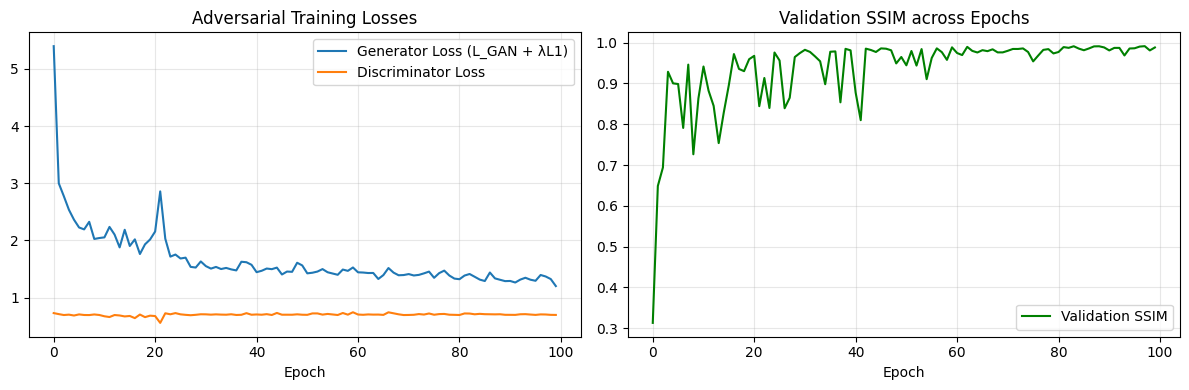

In [4]:
#Cella 4
generator = UNet3DGenerator().to(DEVICE)
discriminator = CNN3DDiscriminator().to(DEVICE)

opt_G = torch.optim.Adam(generator.parameters(), lr=Config.LR, betas=(Config.BETA1, Config.BETA2))
opt_D = torch.optim.Adam(discriminator.parameters(), lr=Config.LR, betas=(Config.BETA1, Config.BETA2))

criterion_gan = nn.BCELoss()
criterion_l1  = nn.L1Loss()

history = {"G_loss": [], "D_loss": [], "val_mse": [], "val_ssim": []}
best_val_mse = float("inf")
weights_path = os.path.join(Config.OUTPUT_DIR, "unet3d_generator.pth")

print(f"Inizio training 3D U-Net-GAN per {Config.EPOCHS} epoche...")
start_time = time.time()

for epoch in range(1, Config.EPOCHS + 1):
    generator.train()
    discriminator.train()
    
    epoch_g_loss = 0.0
    epoch_d_loss = 0.0
    
    for seed_vol, target_vol, _ in train_loader:
        seed_vol = seed_vol.to(DEVICE)
        target_vol = target_vol.to(DEVICE)
        bs = seed_vol.size(0)
        
        # Label smoothing leggero per stabilità (come indicato in Sez. IV)
        real_labels = torch.full((bs, 1), 0.9, device=DEVICE)
        fake_labels = torch.full((bs, 1), 0.0, device=DEVICE)
        
        # ---------------------
        # 1. Train Discriminator
        # ---------------------
        opt_D.zero_grad()
        out_real = discriminator(target_vol)
        loss_d_real = criterion_gan(out_real, real_labels)
        
        fake_vol = generator(seed_vol)
        out_fake = discriminator(fake_vol.detach())
        loss_d_fake = criterion_gan(out_fake, fake_labels)
        
        loss_D = 0.5 * (loss_d_real + loss_d_fake)
        loss_D.backward()
        opt_D.step()
        
        # ---------------------
        # 2. Train Generator (Eq. 4: L_total = L_GAN + \lambda * L_recon)
        # ---------------------
        opt_G.zero_grad()
        out_fake_for_g = discriminator(fake_vol)
        loss_g_gan = criterion_gan(out_fake_for_g, torch.ones((bs, 1), device=DEVICE))
        loss_g_l1  = criterion_l1(fake_vol, target_vol)
        
        loss_G = loss_g_gan + Config.LAMBDA_L1 * loss_g_l1
        loss_G.backward()
        opt_G.step()
        
        epoch_g_loss += loss_G.item() * bs
        epoch_d_loss += loss_D.item() * bs
        
    epoch_g_loss /= len(train_loader.dataset)
    epoch_d_loss /= len(train_loader.dataset)
    
    # Validazione
    generator.eval()
    val_mse_list, val_ssim_list = [], []
    with torch.no_grad():
        for seed_vol, target_vol, _ in val_loader:
            seed_vol = seed_vol.to(DEVICE)
            target_vol = target_vol.to(DEVICE)
            pred_vol = generator(seed_vol)
            
            mse_batch = F.mse_loss(pred_vol, target_vol).item()
            val_mse_list.append(mse_batch)
            
            # Calcolo SSIM sulla slice centrale per monitoraggio veloce
            p_np = pred_vol[:, 0, 5, :, :].cpu().numpy()
            t_np = target_vol[:, 0, 5, :, :].cpu().numpy()
            for i in range(p_np.shape[0]):
                val_ssim_list.append(ssim_metric(t_np[i], p_np[i], data_range=1.0))
                
    mean_val_mse = float(np.mean(val_mse_list))
    mean_val_ssim = float(np.mean(val_ssim_list))
    
    history["G_loss"].append(epoch_g_loss)
    history["D_loss"].append(epoch_d_loss)
    history["val_mse"].append(mean_val_mse)
    history["val_ssim"].append(mean_val_ssim)
    
    if mean_val_mse < best_val_mse:
        best_val_mse = mean_val_mse
        torch.save(generator.state_dict(), weights_path)
        
    if epoch == 1 or epoch % 10 == 0 or epoch == Config.EPOCHS:
        elapsed = time.time() - start_time
        print(f"Epoch [{epoch:03d}/{Config.EPOCHS:03d}] | D_Loss: {epoch_d_loss:.4f} | G_Loss: {epoch_g_loss:.4f} | Val MSE: {mean_val_mse:.5f} | Val SSIM: {mean_val_ssim:.4f} | Time: {elapsed:.1f}s")

print(f"\nTraining completato! Miglior modello salvato in: {weights_path}")

# Plot delle curve di Loss e Metriche
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["G_loss"], label="Generator Loss (L_GAN + λL1)")
axes[0].plot(history["D_loss"], label="Discriminator Loss")
axes[0].set_title("Adversarial Training Losses")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history["val_ssim"], color="green", label="Validation SSIM")
axes[1].set_title("Validation SSIM across Epochs")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
#Cella 5
generator.load_state_dict(torch.load(weights_path, map_location=DEVICE))
generator.eval()

test_mse, test_mae, test_psnr, test_ssim = [], [], [], []

with torch.no_grad():
    for seed_vol, target_vol, _ in test_loader:
        seed_vol = seed_vol.to(DEVICE)
        target_vol = target_vol.to(DEVICE)
        pred_vol = generator(seed_vol)
        
        p_np = pred_vol.cpu().numpy()[:, 0]   # [B, 10, 128, 128]
        t_np = target_vol.cpu().numpy()[:, 0] # [B, 10, 128, 128]
        
        for b in range(p_np.shape[0]):
            case_mse = np.mean((p_np[b] - t_np[b]) ** 2)
            case_mae = np.mean(np.abs(p_np[b] - t_np[b]))
            
            slice_psnr, slice_ssim = [], []
            for s in range(Config.NUM_SLICES):
                slice_psnr.append(psnr_metric(t_np[b, s], p_np[b, s], data_range=1.0))
                slice_ssim.append(ssim_metric(t_np[b, s], p_np[b, s], data_range=1.0))
                
            test_mse.append(case_mse)
            test_mae.append(case_mae)
            test_psnr.append(np.mean(slice_psnr))
            test_ssim.append(np.mean(slice_ssim))

print("==========================================================")
print("     RISULTATI QUANTITATIVI SUL TEST SET (Sez. VI-A)      ")
print("==========================================================")
print(f"Mean MSE  : {np.mean(test_mse):.5f}  (Paper ref: 0.0059)")
print(f"Mean MAE  : {np.mean(test_mae):.5f}  (Paper ref: 0.0283)")
print(f"Mean PSNR : {np.mean(test_psnr):.2f} dB (Paper ref: 24.13 dB)")
print(f"Mean SSIM : {np.mean(test_ssim):.4f}  (Paper ref: 0.9296)")
print("==========================================================")

     RISULTATI QUANTITATIVI SUL TEST SET (Sez. VI-A)      
Mean MSE  : 0.00009  (Paper ref: 0.0059)
Mean MAE  : 0.00405  (Paper ref: 0.0283)
Mean PSNR : 42.66 dB (Paper ref: 24.13 dB)
Mean SSIM : 0.9932  (Paper ref: 0.9296)
